# 4 — Prédire une variation et donner du poids aux changements rares

**Question :** Le lissage des pics vient-il aussi de la cible et de la pondération, indépendamment de l'information disponible ?

## Protocole commun

Prévision émise à **00 h UTC du jour cible** : toutes les entrées proviennent de la veille
ou de jours antérieurs, avec une dernière observation à 23 h UTC. La cible est le maximum
des 24 températures horaires du jour cible UTC. ERA5 est une réanalyse disponible avec retard :
cette étude rétrospective ne simule pas la disponibilité d'un service de prévision en direct.

Le fichier `experiments/protocol.json` fixe les hypothèses et les paramètres. On évalue trois
fenêtres successives couvrant 2025, avec entraînement croissant. Dans chaque fenêtre,
les 90 derniers jours de développement servent à l'arrêt anticipé ; une journée est purgée
aux frontières. On réentraîne ensuite sur le développement avec le nombre d'arbres retenu.
Le choix entre variantes se fait sur la MAE pondérée par les effectifs des fenêtres 2025,
**avant** l'évaluation sur janvier–septembre 2026. La persistance reste une référence séparée.

L'année 2026 ayant déjà été consultée auparavant, ses résultats sont exploratoires.
Les modifications du protocole doivent produire une nouvelle expérience et un nouveau commit.
Aucun hyperparamètre n'est ajusté pour obtenir un meilleur score sur 2026.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "flake.nix").exists())
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from research_features import load_research_data, protocol
from research_evaluation import evaluate_suite, summarize_cv
from research_reporting import report, plot_cells
pd.set_option("display.max_columns", 20)


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


## Variables et hypothèse

On compare Tmax(J+1) directement à ΔTmax = Tmax(J+1) − Tmax(J).
Pour la seconde cible, la prévision finale est Tmax(J) + variation prédite.
Ainsi le niveau connu peut être réutilisé sans obliger les arbres à apprendre toute l'échelle
des températures absolues. La persistance correspond à une variation prédite nulle.

On croise les deux cibles avec deux jeux d'entrées fixés : local + horaire, puis le même jeu
enrichi de tous les voisins et indicateurs physiques. Aucun jeu n'est choisi à partir du test.
Une variante pondère par 3 les observations **d'entraînement** dont |ΔTmax| ≥ 4 °C ; toutes les
autres gardent un poids de 1. Les scores et la validation restent non pondérés.
Cette pondération peut aider les variations rares tout en dégradant la MAE globale : on montre les deux.
Ridge avec alpha fixé complète le contrôle algorithmique, sans optimisation sur 2026.

In [2]:
frame, groups, cells, data_path = load_research_data(spatial=True)
print(f"{len(frame)} paires : {frame['target_date'].min().date()} → {frame['target_date'].max().date()}")
display(pd.DataFrame([{"groupe": k, "nombre_variables": len(v)} for k, v in groups.items()]))
display(frame[["date", "target_date", "issue_time", "last_observation_time", "temperature_max", "tmax_next_day"]].head())
assert (frame["last_observation_time"] < frame["issue_time"]).all()


994 paires : 2024-01-04 → 2026-09-23


,groupe,nombre_variables
0,daily,18
1,hourly,28
2,local_raw,28
3,regional_raw,28
4,physics,10
5,upwind,8


,date,target_date,issue_time,last_observation_time,temperature_max,tmax_next_day
0,2024-01-03,2024-01-04,2024-01-04 00:00:00+00:00,2024-01-03 23:00:00+00:00,12.7,13.2
1,2024-01-04,2024-01-05,2024-01-05 00:00:00+00:00,2024-01-04 23:00:00+00:00,13.2,10.8
2,2024-01-05,2024-01-06,2024-01-06 00:00:00+00:00,2024-01-05 23:00:00+00:00,10.8,9.3
3,2024-01-06,2024-01-07,2024-01-07 00:00:00+00:00,2024-01-06 23:00:00+00:00,9.3,6.6
4,2024-01-07,2024-01-08,2024-01-08 00:00:00+00:00,2024-01-07 23:00:00+00:00,6.6,3.8


In [3]:
local = groups["daily"] + groups["hourly"]
spatial = local + groups["local_raw"] + groups["regional_raw"] + groups["physics"] + groups["upwind"]
variants = {
    "xgb_local_direct": {"columns": local},
    "xgb_local_delta": {"columns": local, "target": "delta"},
    "xgb_spatial_direct": {"columns": spatial},
    "xgb_spatial_delta": {"columns": spatial, "target": "delta"},
    "xgb_spatial_delta_weighted": {"columns": spatial, "target": "delta", "weighting": "changes"},
    "ridge_spatial_delta": {"columns": spatial, "target": "delta", "algorithm": "ridge"},
}


## Expérience et enregistrement

Le code commun est dans `scripts/research_features.py` et `scripts/research_evaluation.py`.
Chaque variante utilise les mêmes lignes ; les colonnes et les paramètres sont explicitement
enregistrés avec les nombres d'arbres, les empreintes du dataset et du code.
Les températures restent en °C. XGBoost ne reçoit pas de standardisation globale ; Ridge
ajuste son standardiseur uniquement sur la période d'entraînement de chaque fenêtre.

In [4]:
scores, predictions, lag_scores, intervals, selected, output = evaluate_suite(
    frame, variants, "04_changes_and_weighting", data_path
)


04_changes_and_weighting — cv_2025_spring : 120 jours


04_changes_and_weighting — cv_2025_summer : 123 jours


04_changes_and_weighting — cv_2025_autumn : 122 jours


Choix figé sur les fenêtres 2025 : ridge_spatial_delta


04_changes_and_weighting — test_2026 : 266 jours


## Résultats : niveau, variations et pics

La MAE globale est la métrique principale. Les fortes variations sont définies **avant** les résultats
par |Tmax(J+1) − Tmax(J)| ≥ 4 °C, avec refroidissements et réchauffements séparés.
Les journées chaudes utilisent le 90e percentile des cibles du développement de chaque fenêtre,
jamais un seuil calculé sur le test. Il ne s'agit pas d'une définition de canicule.

Le gain positif signifie une erreur inférieure à la persistance. Les intervalles descriptifs
par bootstrap de blocs de sept jours tiennent partiellement compte de l'autocorrélation,
sans garantir la généralisation à d'autres années ni corriger les comparaisons multiples.

Moyenne pondérée des trois fenêtres 2025 (choix du modèle) :


,MAE_C,MAE_large_changes_C,n,n_large_changes,gain_vs_persistence_C
variant,,,,,
persistence,2.176,5.575,365,55,0.000
xgb_local_direct,2.059,3.682,365,55,0.117
xgb_local_delta,2.068,4.821,365,55,0.109
xgb_spatial_direct,2.070,3.417,365,55,0.107
xgb_spatial_delta,2.003,4.611,365,55,0.173
xgb_spatial_delta_weighted,2.038,4.724,365,55,0.139
ridge_spatial_delta,1.850,3.555,365,55,0.326


Choix sur 2025, maintenu pour 2026 : ridge_spatial_delta
Test descriptif 2026 — MAE en °C et effectifs :


,MAE_C,RMSE_C,bias_C,n,n_large_changes,MAE_large_changes_C,MAE_cooling_C,MAE_warming_C,MAE_warm_days_C,gain_vs_persistence_C
variant,,,,,,,,,,
persistence,2.039,2.778,-0.091,266,41,5.683,5.695,5.670,2.379,0.000
xgb_local_direct,2.353,3.301,-1.355,266,41,3.742,2.588,4.953,3.756,-0.314
xgb_local_delta,1.814,2.452,-0.358,266,41,4.279,3.634,4.956,2.086,0.225
xgb_spatial_direct,2.465,3.414,-1.799,266,41,3.752,2.147,5.436,3.922,-0.426
xgb_spatial_delta,1.717,2.371,-0.131,266,41,4.519,3.998,5.067,1.847,0.321
xgb_spatial_delta_weighted,1.741,2.397,0.036,266,41,4.700,4.477,4.934,1.865,0.298
ridge_spatial_delta,1.766,2.361,-0.518,266,41,3.642,2.726,4.604,2.080,0.273


Gain vs persistance : intervalle descriptif par blocs de 7 jours (sans correction pour comparaisons multiples) :


,gain_low_C,gain_high_C
variant,,
persistence,0.000,0.000
ridge_spatial_delta,0.093,0.457
xgb_local_delta,0.075,0.384
xgb_local_direct,-0.810,0.114
xgb_spatial_delta,0.209,0.438
xgb_spatial_delta_weighted,0.194,0.403
xgb_spatial_direct,-0.912,0.007


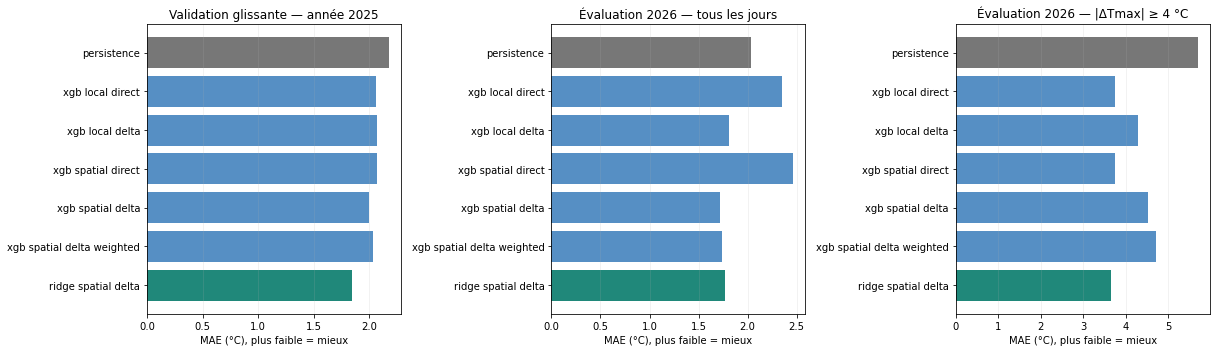

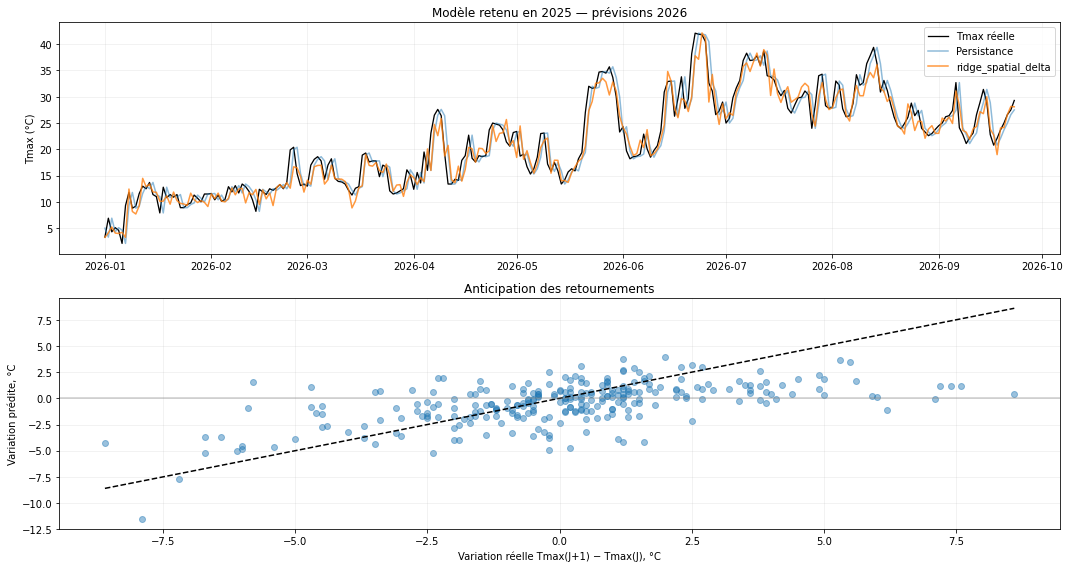

Diagnostic de décalage : vérité comparée à date_cible + décalage. -1 = la veille.


,MAE_truth_date_plus_-1_C,MAE_truth_date_plus_0_C,MAE_truth_date_plus_1_C
variant,,,
persistence,0.000,2.040,3.060
xgb_local_direct,1.847,2.354,3.010
xgb_local_delta,1.033,1.817,2.768
xgb_spatial_direct,2.138,2.471,3.120
xgb_spatial_delta,0.742,1.722,2.775
xgb_spatial_delta_weighted,0.683,1.745,2.752
ridge_spatial_delta,1.512,1.768,2.743


Un minimum à -1 signale une ressemblance avec la veille ; il ne prouve pas une erreur de dates.
MAE par mois cible, mêmes jours pour tous les modèles :


variant,persistence,ridge_spatial_delta,xgb_local_delta,xgb_local_direct,xgb_spatial_delta,xgb_spatial_delta_weighted,xgb_spatial_direct
month,,,,,,,
2026-01,1.687,1.316,1.333,1.376,1.262,1.331,1.338
2026-02,1.454,1.408,1.521,1.303,1.451,1.469,1.235
2026-03,1.526,1.344,1.485,1.563,1.487,1.530,1.883
2026-04,2.423,2.385,2.287,2.027,2.280,2.229,2.528
2026-05,2.158,2.143,2.043,2.539,2.060,2.065,2.825
2026-06,2.770,2.318,2.074,3.517,2.086,2.128,4.033
2026-07,2.129,1.653,2.085,3.921,1.675,1.666,3.649
2026-08,2.045,1.752,1.767,2.957,1.474,1.507,2.725
2026-09,2.170,1.515,1.694,1.743,1.677,1.747,1.705


Les effectifs des fortes variations sont limités ; pas de conclusion causale sur les fronts météorologiques.


In [5]:
report(scores, predictions, lag_scores, intervals, selected, output)


## Géométrie du voisinage

Coordonnées des cellules réellement retournées, sans présumer une station de mesure.

,lat,lon
point,,
center,47.25,-1.50
local_east,47.25,-0.50
local_north,48.00,-1.50
local_south,46.50,-1.50
local_west,47.25,-2.50
regional_east,47.25,1.00
regional_north,49.00,-1.50
regional_south,45.50,-1.50
regional_west,47.25,-4.25


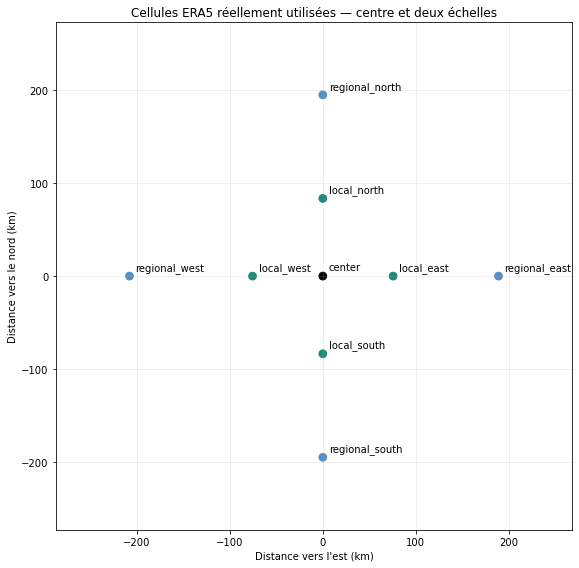

In [6]:
display(cells)
plot_cells(cells, output)


## Interprétation et limites

Un gain global sans gain sur les refroidissements ne valide pas l'hypothèse d'anticipation des fronts.
À l'inverse, un gain sur quelques pics peut être instable : regarder les effectifs, les trois fenêtres
2025 et les mois de 2026. Ne pas confondre mauvaise information, décalage d'alignement et faible
extrapolation du modèle. Cette étude ne mesure pas directement les fronts ni les masses d'air.
L'absence de gain avec ces variables ne prouve pas que toute information spatiale est inutile.

Avec moins de trois années et environ mille journées, les réseaux neuronaux ne sont pas la prochaine
étape automatique. Une confirmation sur des années supplémentaires et des prévisions archivées
disponibles à l'heure d'émission sera nécessaire avant une conclusion opérationnelle.

Sources : [Open-Meteo, réanalyse et paramètres](https://open-meteo.com/en/docs/historical-weather-api),
[évaluation temporelle](https://scikit-learn.org/stable/modules/cross_validation.html),
[complexité et régularisation XGBoost](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html).

In [7]:
cv = summarize_cv(scores)
test = scores.loc[scores["window"].eq("test_2026")].set_index("variant")
print(f"Variante choisie en 2025 : {selected}")
print(f"MAE 2025 : {cv.loc[selected, 'MAE_C']:.3f} °C ; persistance : {cv.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 : {test.loc[selected, 'MAE_C']:.3f} °C ; persistance : {test.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 sur fortes variations : {test.loc[selected, 'MAE_large_changes_C']:.3f} °C ; n = {test.loc[selected, 'n_large_changes']}")
print(f"Traces et figures enregistrées dans {output.relative_to(PROJECT_ROOT)}")


Variante choisie en 2025 : ridge_spatial_delta
MAE 2025 : 1.850 °C ; persistance : 2.176 °C
MAE 2026 : 1.766 °C ; persistance : 2.039 °C
MAE 2026 sur fortes variations : 3.642 °C ; n = 41
Traces et figures enregistrées dans experiments/results/04_changes_and_weighting
